In [3]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from initial_state import ValidationSpec
from controllers.sindy_mpc import SINDyMPCController, SINDyMPCConfig
from models.sindy import SINDyConfig, SINDyDynamicsModel
from models.dataset_views import (
    load_control_dataset, flatten_supervised, kfold_stratified_by_angle,
)
from models.lqr_utils import discrete_lqr_gain
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics

DATASET      = ROOT / "data/full_example/random_walk_dataset.npz"
MPC_ARTIFACT = ROOT / "artifacts/controllers/sindy_mpc.pkl"
VAL_SPEC     = ROOT / "artifacts/validation/sindy_lqr_val_spec.npz"
MPC_ROLLOUTS = ROOT / "artifacts/validation/sindy_mpc_stress_rollouts.npz"
LQR_FOLD_METRICS = ROOT / "artifacts/validation/sindy_lqr_fold_metrics.npz"
MPC_FOLD_METRICS = ROOT / "artifacts/validation/sindy_mpc_fold_metrics.npz"

N_FOLDS     = 5
T_END       = 20.0
DT          = 0.02
FORCE_LIMIT = 5.0
SEED        = 0

## 1. Load Spec, Baseline Rollouts, and Hyperparameters

Requires `07a_sindy_mpc_stress_test.ipynb` to have been run first.

In [4]:
for path in (VAL_SPEC, MPC_ROLLOUTS, MPC_ARTIFACT):
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found.\n"
            "Run 05a_sindy_lqr_stress_test.ipynb and 07a_sindy_mpc_stress_test.ipynb first."
        )

spec     = ValidationSpec.load(VAL_SPEC)
feas_idx = np.where(spec.feasible)[0]
n_feas   = len(feas_idx)
print(f"Validation spec: {n_feas}/{spec.n} feasible cases")

_d = np.load(MPC_ROLLOUTS)
states_arr = _d["states"]
inputs_arr = _d["inputs"]
t_arr      = _d["t"]
rollout_ok = _d["success"].astype(bool)
print(f"Baseline MPC rollouts: {rollout_ok.sum()} successful")

baseline = SINDyMPCController.load(MPC_ARTIFACT)
best_thr   = baseline.metadata["model"]["config"]["threshold"]
best_ridge = baseline.metadata["model"]["config"]["ridge"]
best_horizon = int(baseline.metadata["horizon"])
q = np.asarray(baseline.metadata["Q"])
r = np.asarray(baseline.metadata["R"])

print(f"Baseline hyperparams: threshold={best_thr}  ridge={best_ridge}  "
      f"horizon={best_horizon}")

Validation spec: 100/100 feasible cases
Baseline MPC rollouts: 100 successful
Baseline hyperparams: threshold=0.005  ridge=1e-06  horizon=20


## 2. Original Training Dataset

In [5]:
ds = load_control_dataset(DATASET)
all_traj_idx = np.arange(ds.num_trajectories)
x_orig, _, x_next_orig = flatten_supervised(ds, all_traj_idx)
print(f"Original dataset: {x_orig.shape[0]:,} transition pairs")

Original dataset: 499,500 transition pairs


## 3. Five-Fold Stratified Splits

Same splits as `05b_sindy_lqr_crossval.ipynb` (same seed) for direct comparison.

In [6]:
feas_angles = spec.angles_deg[feas_idx]
splits = kfold_stratified_by_angle(n_feas, feas_angles, k=N_FOLDS, seed=SEED)

print(f"{N_FOLDS}-fold splits (stratified by angle):")
for fold, (train_i, val_i) in enumerate(splits):
    val_angles = feas_angles[val_i]
    print(f"  Fold {fold + 1}: train={len(train_i)}  val={len(val_i)}  "
          f"val_angle=[{val_angles.min():.1f}, {val_angles.max():.1f}] deg")

5-fold splits (stratified by angle):
  Fold 1: train=80  val=20  val_angle=[6.8, 84.7] deg
  Fold 2: train=80  val=20  val_angle=[6.9, 86.0] deg
  Fold 3: train=80  val=20  val_angle=[8.2, 86.5] deg
  Fold 4: train=80  val=20  val_angle=[8.5, 87.4] deg
  Fold 5: train=80  val=20  val_angle=[8.8, 89.4] deg


## 4. Cross-Validation Loop

For each fold: combine original dataset pairs + 80 train-fold MPC rollout pairs, fit
SINDy with baseline hyperparams, compute DARE terminal cost, build MPC, evaluate on
20 held-out initial states.

In [7]:
fold_results = []
fold_equations = []

for fold, (train_i, val_i) in enumerate(splits):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} ---")

    # Build training pairs from MPC baseline rollouts
    zu_list, xn_list = [], []
    for local_i in train_i:
        global_i = int(feas_idx[local_i])
        if not rollout_ok[global_i]:
            continue
        s = states_arr[global_i]       # (4, n_steps)
        u = inputs_arr[global_i]       # (n_steps,)
        sk = s.T[:-1]                  # (n_steps-1, 4)
        uk = u[:-1, None]              # (n_steps-1, 1)
        zu = np.concatenate([sk, uk], axis=1)  # (n_steps-1, 5)
        xn = s.T[1:]
        if np.all(np.isfinite(zu)) and np.all(np.isfinite(xn)):
            zu_list.append(zu)
            xn_list.append(xn)

    if zu_list:
        x_fold = np.vstack(zu_list)
        x_next_fold = np.vstack(xn_list)
        x_combined = np.vstack([x_orig, x_fold])
        x_next_combined = np.vstack([x_next_orig, x_next_fold])
        n_rollout_pairs = x_fold.shape[0]
    else:
        x_combined = x_orig
        x_next_combined = x_next_orig
        n_rollout_pairs = 0

    print(f"  Training pairs: {x_orig.shape[0]:,} original + "
          f"{n_rollout_pairs:,} rollout = {x_combined.shape[0]:,} total")

    # Fit SINDy model with baseline hyperparams
    sindy_config = SINDyConfig(threshold=best_thr, ridge=best_ridge)
    model = SINDyDynamicsModel(config=sindy_config).fit(x_combined, x_next_combined)
    a, b = model.linearize()
    k_gain, p_terminal = discrete_lqr_gain(a, b, q, r)

    mpc_cfg = SINDyMPCConfig(threshold=best_thr, ridge=best_ridge, horizon=best_horizon)
    fold_ctrl = SINDyMPCController(
        model=model,
        config=mpc_cfg,
        q=q, r=r,
        p_terminal=p_terminal,
        k_fallback=k_gain,
        force_limit=FORCE_LIMIT,
    )
    fold_equations.append(model.equations())
    print("  Equations:")
    for eq in model.equations():
        print(f"    {eq}")

    # Evaluate on held-out initial states
    for local_i in val_i:
        global_i = int(feas_idx[local_i])
        x0 = spec.initial_states[global_i]
        result = rollout_controller(
            fold_ctrl, x0, t_end=T_END, dt=DT, force_limit=FORCE_LIMIT,
        )
        m = rollout_metrics(result.t, result.y, result.u, result.control_times_sec)
        fold_results.append({
            "case":      global_i,
            "fold":      fold,
            "angle_deg": float(spec.angles_deg[global_i]),
            "force_N":   float(spec.forces[global_i]),
            **m,
        })

    fold_succ = sum(1 for r in fold_results if r["fold"] == fold and r.get("success"))
    fold_n    = sum(1 for r in fold_results if r["fold"] == fold)
    print(f"  Fold {fold + 1} held-out: {fold_succ}/{fold_n} success")

print(f"\n=== Cross-validation complete: {len(fold_results)} held-out evaluations ===")


--- Fold 1/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Equations:
    x_next = 0.9994*x + 0.01581*x_dot + -0.006553*cos(theta)-1
    x_dot_next = 0.9989*x_dot + 0.01738*u + -0.02317*sin(theta)
    theta_next = 1*theta + 0.01067*theta_dot
    theta_dot_next = 0.9991*theta_dot + -0.007447*u + 0.2457*sin(theta) + 0.01794*u*cos(theta)


/Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/.venv/lib/python3.12/site-packages/cvxpy/problems/problem.py:1510: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


  Fold 1 held-out: 0/20 success

--- Fold 2/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Equations:
    x_next = 0.9994*x + 0.0158*x_dot + -0.006529*cos(theta)-1
    x_dot_next = 0.9989*x_dot + 0.01739*u + -0.02318*sin(theta)
    theta_next = 1*theta + 0.01066*theta_dot
    theta_dot_next = 0.9991*theta_dot + -0.007618*u + 0.2454*sin(theta) + 0.01774*u*cos(theta)
  Fold 2 held-out: 0/20 success

--- Fold 3/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Equations:
    x_next = 0.9994*x + 0.01579*x_dot + -0.006539*cos(theta)-1
    x_dot_next = 0.9989*x_dot + 0.0174*u + -0.02315*sin(theta)
    theta_next = 1*theta + 0.01066*theta_dot
    theta_dot_next = 0.999*theta_dot + -0.007196*u + 0.2455*sin(theta) + 0.0181*u*cos(theta)
  Fold 3 held-out: 0/20 success

--- Fold 4/5 ---
  Training pairs: 499,500 original + 80,000 rollout = 579,500 total
  Equations:
    x_next = 0.9994*x + 0.0158*x_dot + -0.00653*cos(theta)-1
    x_dot_next =

## 5. Results

In [8]:
print(f"{'Fold':>5}  {'n':>4}  {'success':>8}  {'succ%':>6}  "
      f"{'settle_med':>10}  {'cost_med':>8}")
print("-" * 55)
for fold in range(N_FOLDS):
    recs = [r for r in fold_results if r["fold"] == fold]
    n_f  = len(recs)
    succ = sum(1 for r in recs if r.get("success"))
    costs_f = [r["cost"] for r in recs if "cost" in r]
    st_f    = [r["settle_and_remain_time"] for r in recs
               if r.get("settle_and_remain_time") is not None]
    print(f"{fold + 1:>5}  {n_f:>4}  {succ:>8}  "
          f"{100 * succ / max(1, n_f):>5.1f}%  "
          f"{np.median(st_f) if st_f else float('nan'):>10.2f}  "
          f"{np.median(costs_f) if costs_f else float('nan'):>8.1f}")

print("-" * 55)
total_succ = sum(1 for r in fold_results if r.get("success"))
total_n    = len(fold_results)
all_costs  = [r["cost"] for r in fold_results if "cost" in r]
all_st     = [r["settle_and_remain_time"] for r in fold_results
              if r.get("settle_and_remain_time") is not None]
print(f"{'CV':>5}  {total_n:>4}  {total_succ:>8}  "
      f"{100 * total_succ / max(1, total_n):>5.1f}%  "
      f"{np.median(all_st) if all_st else float('nan'):>10.2f}  "
      f"{np.median(all_costs) if all_costs else float('nan'):>8.1f}")

 Fold     n   success   succ%  settle_med  cost_med
-------------------------------------------------------
    1    20         0    0.0%         nan  1196901.4
    2    20         0    0.0%         nan  1252209.4
    3    20         0    0.0%       20.00  1127472.5
    4    20         0    0.0%         nan  1241968.6
    5    20         0    0.0%         nan  1218617.5
-------------------------------------------------------
   CV   100         0    0.0%       20.00  1208512.6


In [9]:
# Compare MPC CV vs LQR CV on same cases
if LQR_FOLD_METRICS.exists():
    lqr_fm = np.load(LQR_FOLD_METRICS)
    cv_cases = {r["case"] for r in fold_results}
    lqr_succ_matched = np.nansum([
        lqr_fm["success"][j]
        for j, c in enumerate(lqr_fm["case"])
        if int(c) in cv_cases and np.isfinite(lqr_fm["success"][j])
    ])
    n_lqr_matched = sum(
        1 for j, c in enumerate(lqr_fm["case"])
        if int(c) in cv_cases and np.isfinite(lqr_fm["success"][j])
    )
    lqr_costs_matched = [
        float(lqr_fm["cost"][j])
        for j, c in enumerate(lqr_fm["case"])
        if int(c) in cv_cases and np.isfinite(lqr_fm["cost"][j])
    ]

    print("\nCV comparison on same held-out initial conditions:")
    print(f"  SINDy-MPC success:  {total_succ}/{total_n}  "
          f"({100 * total_succ / max(1, total_n):.1f}%)")
    print(f"  SINDy-LQR success:  {int(lqr_succ_matched)}/{n_lqr_matched}  "
          f"({100 * lqr_succ_matched / max(1, n_lqr_matched):.1f}%)")
    if all_costs:
        print(f"  MPC median cost:    {np.median(all_costs):.1f}")
    if lqr_costs_matched:
        print(f"  LQR median cost:    {np.median(lqr_costs_matched):.1f}")
else:
    print("LQR fold metrics not found; run 05b_sindy_lqr_crossval.ipynb to enable comparison.")


CV comparison on same held-out initial conditions:
  SINDy-MPC success:  0/100  (0.0%)
  SINDy-LQR success:  5/100  (5.0%)
  MPC median cost:    1208512.6
  LQR median cost:    129706483.7


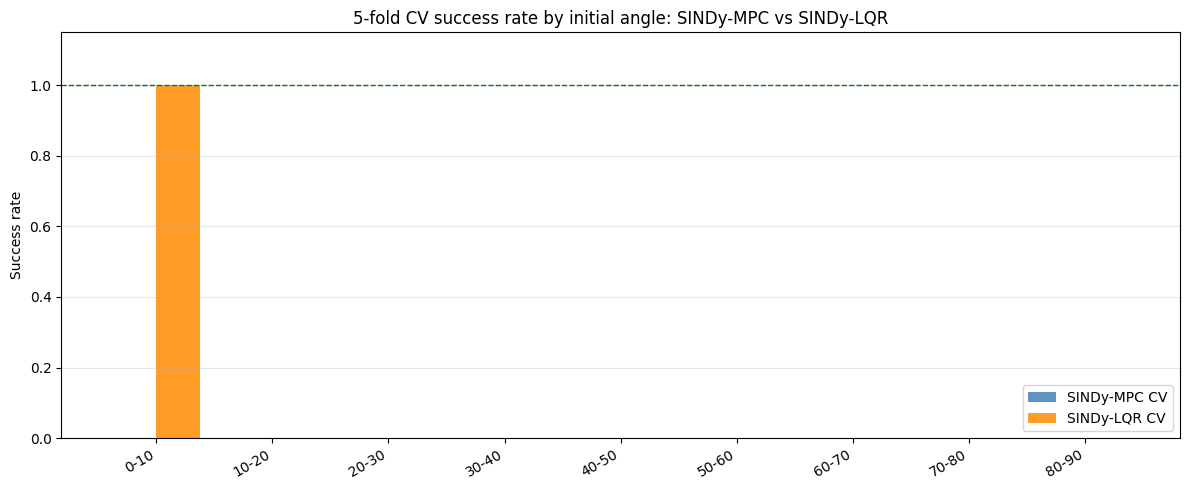

In [10]:
# Plot: CV success rate by angle bucket — MPC vs LQR
angle_bins = np.arange(0, 100, 10)
labels = [f"{int(b)}-{int(b+10)}" for b in angle_bins[:-1]]

mpc_rates, lqr_rates = [], []
for lo, hi in zip(angle_bins[:-1], angle_bins[1:]):
    bucket = [r for r in fold_results if lo <= r["angle_deg"] < hi]
    mpc_rates.append(
        sum(1 for r in bucket if r.get("success")) / max(1, len(bucket))
    )
    if LQR_FOLD_METRICS.exists():
        lqr_b = [
            float(lqr_fm["success"][j])
            for j, c in enumerate(lqr_fm["case"])
            if int(c) in cv_cases
            and lo <= float(spec.angles_deg[int(c)]) < hi
            and np.isfinite(lqr_fm["success"][j])
        ]
        lqr_rates.append(np.mean(lqr_b) if lqr_b else np.nan)
    else:
        lqr_rates.append(np.nan)

x_pos = np.arange(len(labels))
width = 0.38
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x_pos - width / 2, mpc_rates, width=width,
       color="steelblue", alpha=0.85, label="SINDy-MPC CV")
if any(not np.isnan(v) for v in lqr_rates):
    ax.bar(x_pos + width / 2, lqr_rates, width=width,
           color="darkorange", alpha=0.85, label="SINDy-LQR CV")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylabel("Success rate")
ax.set_title("5-fold CV success rate by initial angle: SINDy-MPC vs SINDy-LQR")
ax.set_ylim(0, 1.15)
ax.axhline(1.0, color="green", linestyle="--", linewidth=1)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Save Fold Artifacts

In [11]:
def _to_float(v):
    if v is None:
        return np.nan
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan


fold_metrics_to_save = {
    "case":               np.array([r["case"]         for r in fold_results]),
    "fold":               np.array([r["fold"]         for r in fold_results]),
    "angle_deg":          np.array([r["angle_deg"]    for r in fold_results]),
    "force_N":            np.array([r["force_N"]      for r in fold_results]),
    "success":            np.array([float(r.get("success", np.nan))  for r in fold_results]),
    "no_fall":            np.array([float(r.get("no_fall", np.nan))  for r in fold_results]),
    "settle_and_remain_time": np.array(
        [_to_float(r.get("settle_and_remain_time")) for r in fold_results]
    ),
    "cost":               np.array([_to_float(r.get("cost"))               for r in fold_results]),
    "max_abs_theta":      np.array([_to_float(r.get("max_abs_theta"))      for r in fold_results]),
    "control_energy":     np.array([_to_float(r.get("control_energy"))     for r in fold_results]),
    "settled_fraction":   np.array([_to_float(r.get("settled_fraction"))   for r in fold_results]),
}

MPC_FOLD_METRICS.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(MPC_FOLD_METRICS, **fold_metrics_to_save)
print(f"Saved fold metrics to {MPC_FOLD_METRICS}")
print(f"  {len(fold_results)} rows, {len(fold_metrics_to_save)} columns")

Saved fold metrics to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_mpc_fold_metrics.npz
  100 rows, 11 columns
